# Análise Exploratória e Gráfico de Dispersão: Vendas de Sorvete vs. Temperatura

**Autor:** Arthur Ferreira Vertuli  
**Curso:** Tecnologia em Logística – FATEC São José dos Campos  
**Base de Dados:** `sakshisatre/ice-cream-sales-dataset` (500 registros)

Este notebook realiza a importação da base de dados via `kagglehub`, apresenta as estatísticas descritivas das variáveis (`Temperature` e `Revenue`) e constrói o gráfico de dispersão com reta de regressão linear.

## 1. Instalação e Importação das Bibliotecas e Dataset

In [1]:
import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Download da versão mais recente do dataset no Kaggle
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")
print("Path to dataset files:", path)

# Localiza automaticamente o arquivo CSV baixado
csv_files = glob.glob(os.path.join(path, "*.csv"))
print("Arquivos encontrados:", csv_files)

df = pd.read_csv(csv_files[0])
df.head()

100%|██████████| 2.09k/2.09k [00:00<00:00, 3.44MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1
Arquivos encontrados: ['/root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1/Ice Cream.csv']


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


## 2. Inspeção Estrutural e Estatísticas Descritivas

In [2]:
print("=== Informações Gerais da Base ===")
df.info()

print("\n=== Verificação de Valores Nulos ===")
print(df.isnull().sum())

print("\n=== Estatísticas Descritivas ===")
display(df.describe().round(2))

=== Informações Gerais da Base ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB

=== Verificação de Valores Nulos ===
Temperature    0
Revenue        0
dtype: int64

=== Estatísticas Descritivas ===


,Temperature,Revenue
count,500.00,500.00
mean,22.28,522.06
std,8.10,175.41
min,0.00,10.00
25%,17.18,406.00
50%,22.40,530.00
75%,27.80,643.00
max,45.00,1000.00


## 3. Correlação e Regressão Linear Simples

In [3]:
slope, intercept, r_value, p_value, std_err = stats.linregress(df['Temperature'], df['Revenue'])
r_squared = r_value ** 2

print(f"Coeficiente Angular (Inclinação / Slope): {slope:.4f}")
print(f"Intercepto (Linear): {intercept:.4f}")
print(f"Correlação de Pearson (r): {r_value:.4f}")
print(f"Coeficiente de Determinação (R²): {r_squared:.4f} ({r_squared*100:.2f}%)")
print(f"Valor-p (p-value): {p_value:.4e}")
print(f"Equação da Reta: Revenue = {slope:.2f} * Temperature + {intercept:.2f}")

Coeficiente Angular (Inclinação / Slope): 21.4420
Intercepto (Linear): 44.2968
Correlação de Pearson (r): 0.9898
Coeficiente de Determinação (R²): 0.9798 (97.98%)
Valor-p (p-value): 0.0000e+00
Equação da Reta: Revenue = 21.44 * Temperature + 44.30


## 4. Gráfico de Dispersão (Temperatura vs. Receita)

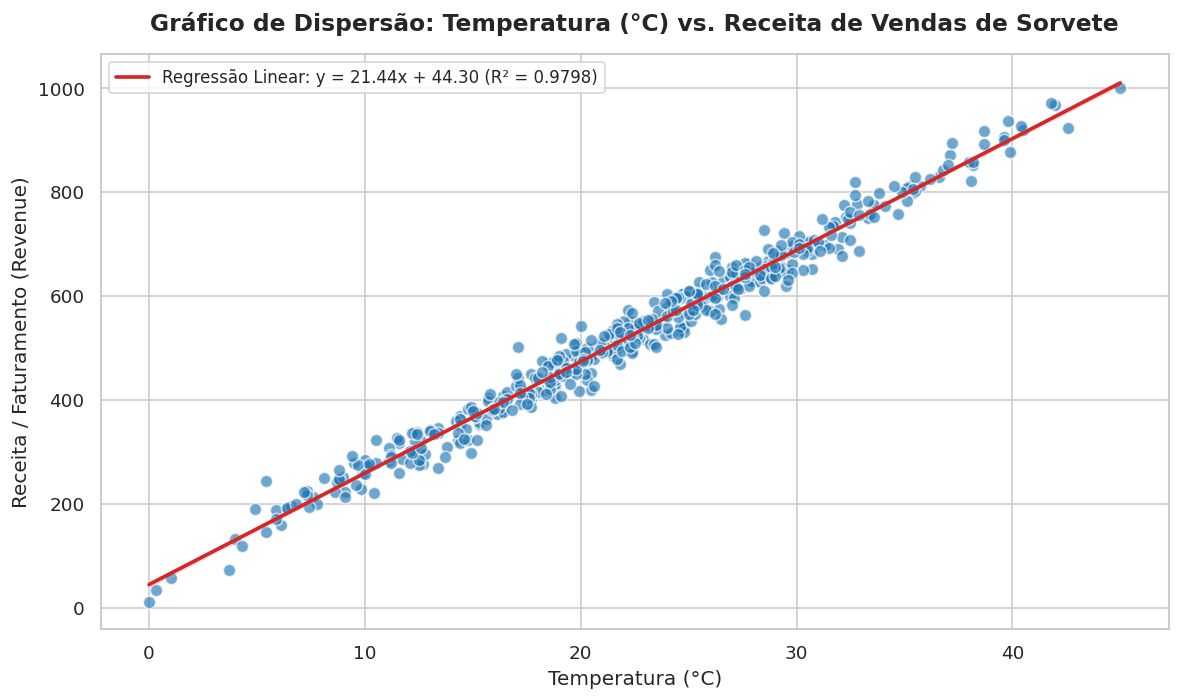

In [4]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=120)

# Gráfico de dispersão com reta de regressão
sns.regplot(
    data=df,
    x='Temperature',
    y='Revenue',
    scatter_kws={'alpha': 0.65, 'color': '#1f77b4', 'edgecolors': 'w', 's': 55, 'label': 'Observações (n = 500)'},
    line_kws={'color': '#d62728', 'linewidth': 2.2, 'label': f'Regressão Linear: y = {slope:.2f}x + {intercept:.2f} (R² = {r_squared:.4f})'}
)

plt.title('Gráfico de Dispersão: Temperatura (°C) vs. Receita de Vendas de Sorvete', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita / Faturamento (Revenue)', fontsize=12)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()